# Email Spam Detection using KNN and SVM

**Assignment:** Classify emails into:
- `0` – Normal / Not Spam
- `1` – Abnormal / Spam

**Dataset:** Email Spam Classification Dataset CSV (Kaggle)

Keep the downloaded CSV file in the same folder as this notebook. Then select **Run → Run All Cells**.

This notebook performs data inspection, preprocessing, train-test split, feature scaling, KNN and SVM classification, and model evaluation/comparison.

In [1]:
# Install any missing libraries
import importlib.util
import subprocess
import sys

packages = {
    "pandas": "pandas",
    "numpy": "numpy",
    "matplotlib": "matplotlib",
    "seaborn": "seaborn",
    "sklearn": "scikit-learn"
}

missing = [package for module, package in packages.items()
           if importlib.util.find_spec(module) is None]

if missing:
    subprocess.check_call([sys.executable, "-m", "pip", "install", *missing])

print("All required libraries are ready.")

All required libraries are ready.


In [2]:
# Import libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    confusion_matrix, classification_report
)

print("Libraries imported successfully.")

Libraries imported successfully.


In [5]:
# 1. Load the dataset
# The CSV should be in the same folder as this notebook.
df = pd.read_csv("spam.csv")

print("Dataset shape:", df.shape)
display(df.head())
print("\nColumn names:")
print(df.columns.tolist())

Dataset shape: (5172, 3002)


,Email No.,the,to,ect,and,for,of,a,you,hou,...,connevey,jay,valued,lay,infrastructure,military,allowing,ff,dry,Prediction
0,Email 1,0,0,1,0,0,0,2,0,0,...,0,0,0,0,0,0,0,0,0,0
1,Email 2,8,13,24,6,6,2,102,1,27,...,0,0,0,0,0,0,0,1,0,0
2,Email 3,0,0,1,0,0,0,8,0,0,...,0,0,0,0,0,0,0,0,0,0
3,Email 4,0,5,22,0,5,1,51,2,10,...,0,0,0,0,0,0,0,0,0,0
4,Email 5,7,6,17,1,5,2,57,0,9,...,0,0,0,0,0,0,0,1,0,0



Column names:
['Email No.', 'the', 'to', 'ect', 'and', 'for', 'of', 'a', 'you', 'hou', 'in', 'on', 'is', 'this', 'enron', 'i', 'be', 'that', 'will', 'have', 'with', 'your', 'at', 'we', 's', 'are', 'it', 'by', 'com', 'as', 'from', 'gas', 'or', 'not', 'me', 'deal', 'if', 'meter', 'hpl', 'please', 're', 'e', 'any', 'our', 'corp', 'can', 'd', 'all', 'has', 'was', 'know', 'need', 'an', 'forwarded', 'new', 't', 'may', 'up', 'j', 'mmbtu', 'should', 'do', 'am', 'get', 'out', 'see', 'no', 'there', 'price', 'daren', 'but', 'been', 'company', 'l', 'these', 'let', 'so', 'would', 'm', 'into', 'xls', 'farmer', 'attached', 'us', 'information', 'they', 'message', 'day', 'time', 'my', 'one', 'what', 'only', 'http', 'th', 'volume', 'mail', 'contract', 'which', 'month', 'more', 'robert', 'sitara', 'about', 'texas', 'nom', 'energy', 'pec', 'questions', 'www', 'deals', 'volumes', 'pm', 'ena', 'now', 'their', 'file', 'some', 'email', 'just', 'also', 'call', 'change', 'other', 'here', 'like', 'b', 'flow', '

In [6]:
# 2. Data preprocessing
# Remove rows with missing values
df = df.dropna().copy()

# The first column contains the email ID/name, so it is not used as a feature.
df = df.iloc[:, 1:]

# The last column contains the target label (0 = not spam, 1 = spam).
X = df.iloc[:, :-1]
y = df.iloc[:, -1]

# Convert features and labels to numeric values
X = X.apply(pd.to_numeric, errors="coerce")
y = pd.to_numeric(y, errors="coerce")

# Remove rows containing invalid numeric values
valid_rows = X.notna().all(axis=1) & y.notna()
X = X.loc[valid_rows]
y = y.loc[valid_rows].astype(int)

print("Features shape:", X.shape)
print("Labels shape:", y.shape)
print("\nClass distribution:")
print(y.value_counts())

Features shape: (5172, 3000)
Labels shape: (5172,)

Class distribution:
Prediction
0    3672
1    1500
Name: count, dtype: int64


In [7]:
# 3. Split dataset into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)

Training data: (4137, 3000)
Testing data: (1035, 3000)


In [8]:
# 4. Feature scaling
# Scaling is important for KNN and SVM.
scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print("Feature scaling completed.")

Feature scaling completed.


In [9]:
# 5. K-Nearest Neighbors (KNN) Classification
knn = KNeighborsClassifier(n_neighbors=5)
knn.fit(X_train_scaled, y_train)

knn_pred = knn.predict(X_test_scaled)

print("KNN model trained successfully.")

KNN model trained successfully.


In [10]:
# 6. Support Vector Machine (SVM) Classification
svm = SVC(kernel="linear")
svm.fit(X_train_scaled, y_train)

svm_pred = svm.predict(X_test_scaled)

print("SVM model trained successfully.")

SVM model trained successfully.


In [11]:
# 7. Evaluate both models
def evaluate_model(name, actual, predicted):
    print("\n", name)
    print("Accuracy :", accuracy_score(actual, predicted))
    print("Precision:", precision_score(actual, predicted, zero_division=0))
    print("Recall   :", recall_score(actual, predicted, zero_division=0))
    print("F1 Score :", f1_score(actual, predicted, zero_division=0))
    print("\nClassification Report:")
    print(classification_report(
        actual, predicted,
        labels=[0, 1],
        target_names=["Not Spam", "Spam"],
        zero_division=0
    ))

evaluate_model("KNN Classification", y_test, knn_pred)
evaluate_model("SVM Classification", y_test, svm_pred)


 KNN Classification
Accuracy : 0.8338164251207729
Precision: 0.6434977578475336
Recall   : 0.9566666666666667
F1 Score : 0.7694369973190348

Classification Report:
              precision    recall  f1-score   support

    Not Spam       0.98      0.78      0.87       735
        Spam       0.64      0.96      0.77       300

    accuracy                           0.83      1035
   macro avg       0.81      0.87      0.82      1035
weighted avg       0.88      0.83      0.84      1035


 SVM Classification
Accuracy : 0.9507246376811594
Precision: 0.9136212624584718
Recall   : 0.9166666666666666
F1 Score : 0.9151414309484193

Classification Report:
              precision    recall  f1-score   support

    Not Spam       0.97      0.96      0.97       735
        Spam       0.91      0.92      0.92       300

    accuracy                           0.95      1035
   macro avg       0.94      0.94      0.94      1035
weighted avg       0.95      0.95      0.95      1035



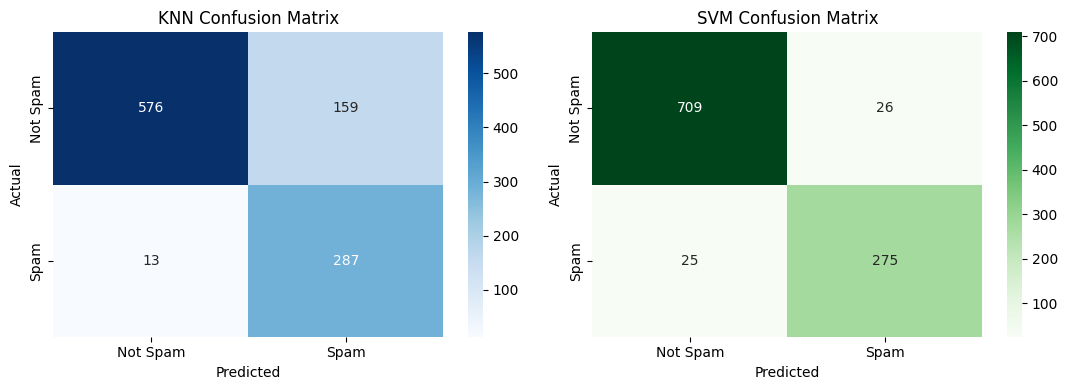

In [12]:
# 8. Confusion matrices
fig, axes = plt.subplots(1, 2, figsize=(11, 4))

sns.heatmap(
    confusion_matrix(y_test, knn_pred, labels=[0, 1]),
    annot=True, fmt="d", cmap="Blues", ax=axes[0]
)
axes[0].set_title("KNN Confusion Matrix")
axes[0].set_xlabel("Predicted")
axes[0].set_ylabel("Actual")
axes[0].set_xticklabels(["Not Spam", "Spam"])
axes[0].set_yticklabels(["Not Spam", "Spam"])

sns.heatmap(
    confusion_matrix(y_test, svm_pred, labels=[0, 1]),
    annot=True, fmt="d", cmap="Greens", ax=axes[1]
)
axes[1].set_title("SVM Confusion Matrix")
axes[1].set_xlabel("Predicted")
axes[1].set_ylabel("Actual")
axes[1].set_xticklabels(["Not Spam", "Spam"])
axes[1].set_yticklabels(["Not Spam", "Spam"])

plt.tight_layout()
plt.show()

In [13]:
# 9. Compare model performance
results = pd.DataFrame({
    "Model": ["KNN", "SVM"],
    "Accuracy": [
        accuracy_score(y_test, knn_pred),
        accuracy_score(y_test, svm_pred)
    ],
    "Precision": [
        precision_score(y_test, knn_pred, zero_division=0),
        precision_score(y_test, svm_pred, zero_division=0)
    ],
    "Recall": [
        recall_score(y_test, knn_pred, zero_division=0),
        recall_score(y_test, svm_pred, zero_division=0)
    ],
    "F1 Score": [
        f1_score(y_test, knn_pred, zero_division=0),
        f1_score(y_test, svm_pred, zero_division=0)
    ]
})

print("Model Performance Comparison:")
display(results)

# Compare models using F1 score
if results.loc[1, "F1 Score"] > results.loc[0, "F1 Score"]:
    print("SVM performs better based on F1 score.")
elif results.loc[1, "F1 Score"] < results.loc[0, "F1 Score"]:
    print("KNN performs better based on F1 score.")
else:
    print("Both models have the same F1 score.")

Model Performance Comparison:


,Model,Accuracy,Precision,Recall,F1 Score
0,KNN,0.833816,0.643498,0.956667,0.769437
1,SVM,0.950725,0.913621,0.916667,0.915141


SVM performs better based on F1 score.


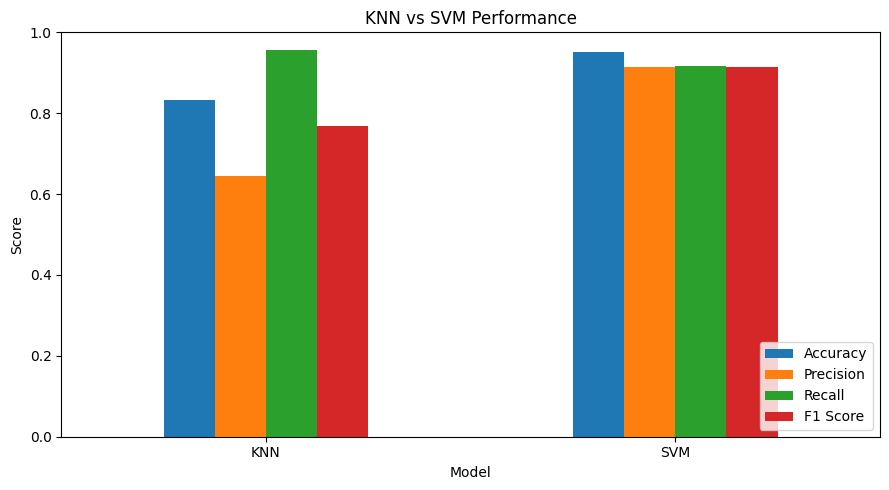

In [14]:
# 10. Performance comparison graph
results.set_index("Model").plot(
    kind="bar", figsize=(9, 5), ylim=(0, 1)
)
plt.title("KNN vs SVM Performance")
plt.ylabel("Score")
plt.xticks(rotation=0)
plt.legend(loc="lower right")
plt.tight_layout()
plt.show()

## Conclusion

Email spam classification was performed using K-Nearest Neighbors (KNN) and Support Vector Machine (SVM).

The dataset was loaded, cleaned, split into training and testing sets, and scaled. Both models were trained and evaluated using Accuracy, Precision, Recall, F1-score and Confusion Matrix.

The comparison table and graph show the performance of both classifiers. The model with the better evaluation scores performs better on the test data.